# FOOTBALL PLAYER TRANSFER VALUE PREDICTION

# Installing Modules

In [1]:
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install seaborn
!pip install xgboost
!pip install scikit-learn

# Importing all necessary Libraries

In [2]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, f1_score, roc_curve, roc_auc_score, mean_squared_error, r2_score, auc
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

# Loading the datafile

In [3]:
# Load the CSV file using pandas
data = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Print the loaded data
print(data)

             Known As           Full Name  Overall  Potential  Value(in Euro)  \
0            L. Messi        Lionel Messi       91         91        54000000   
1          K. Benzema       Karim Benzema       91         91        64000000   
2      R. Lewandowski  Robert Lewandowski       91         91        84000000   
3        K. De Bruyne     Kevin De Bruyne       91         91       107500000   
4           K. Mbappé       Kylian Mbappé       91         95       190500000   
...               ...                 ...      ...        ...             ...   
18534      D. Collins      Darren Collins       47         56          110000   
18535    Yang Dejiang        Dejiang Yang       47         57           90000   
18536       L. Mullan         Liam Mullan       47         67          130000   
18537    D. McCallion    Daithí McCallion       47         61          100000   
18538        N. Rabha         Nabin Rabha       47         50           60000   

      Positions Played Best

# Data Preprocessing

In [4]:
# Replace all occurrences of 0 with NaN
data = data.replace(0, pd.np.nan)

# Drop rows with NaN values
data = data.dropna()
    
# Drop unwanted or less important columns
data = data.drop(labels=['Image Link', 'On Loan', 'National Team Image Link', 'National Team Jersey Number', 'Attacking Work Rate', 'Defensive Work Rate'], axis=1)

# Save the cleaned data back to a CSV file
data.to_csv('cleaned_file.csv', index=False)
print(data)

/var/folders/fd/wt9nfcy93lb9445tcytkhfcm0000gn/T/ipykernel_19932/2061944132.py:2: FutureWarning: The pandas.np module is deprecated and will be removed from pandas in a future version. Import numpy directly instead
  data = data.replace(0, pd.np.nan)


             Known As           Full Name  Overall  Potential  Value(in Euro)  \
0            L. Messi        Lionel Messi       91         91      54000000.0   
1          K. Benzema       Karim Benzema       91         91      64000000.0   
2      R. Lewandowski  Robert Lewandowski       91         91      84000000.0   
3        K. De Bruyne     Kevin De Bruyne       91         91     107500000.0   
4           K. Mbappé       Kylian Mbappé       91         95     190500000.0   
...               ...                 ...      ...        ...             ...   
18534      D. Collins      Darren Collins       47         56        110000.0   
18535    Yang Dejiang        Dejiang Yang       47         57         90000.0   
18536       L. Mullan         Liam Mullan       47         67        130000.0   
18537    D. McCallion    Daithí McCallion       47         61        100000.0   
18538        N. Rabha         Nabin Rabha       47         50         60000.0   

      Positions Played Best

# Pairplots

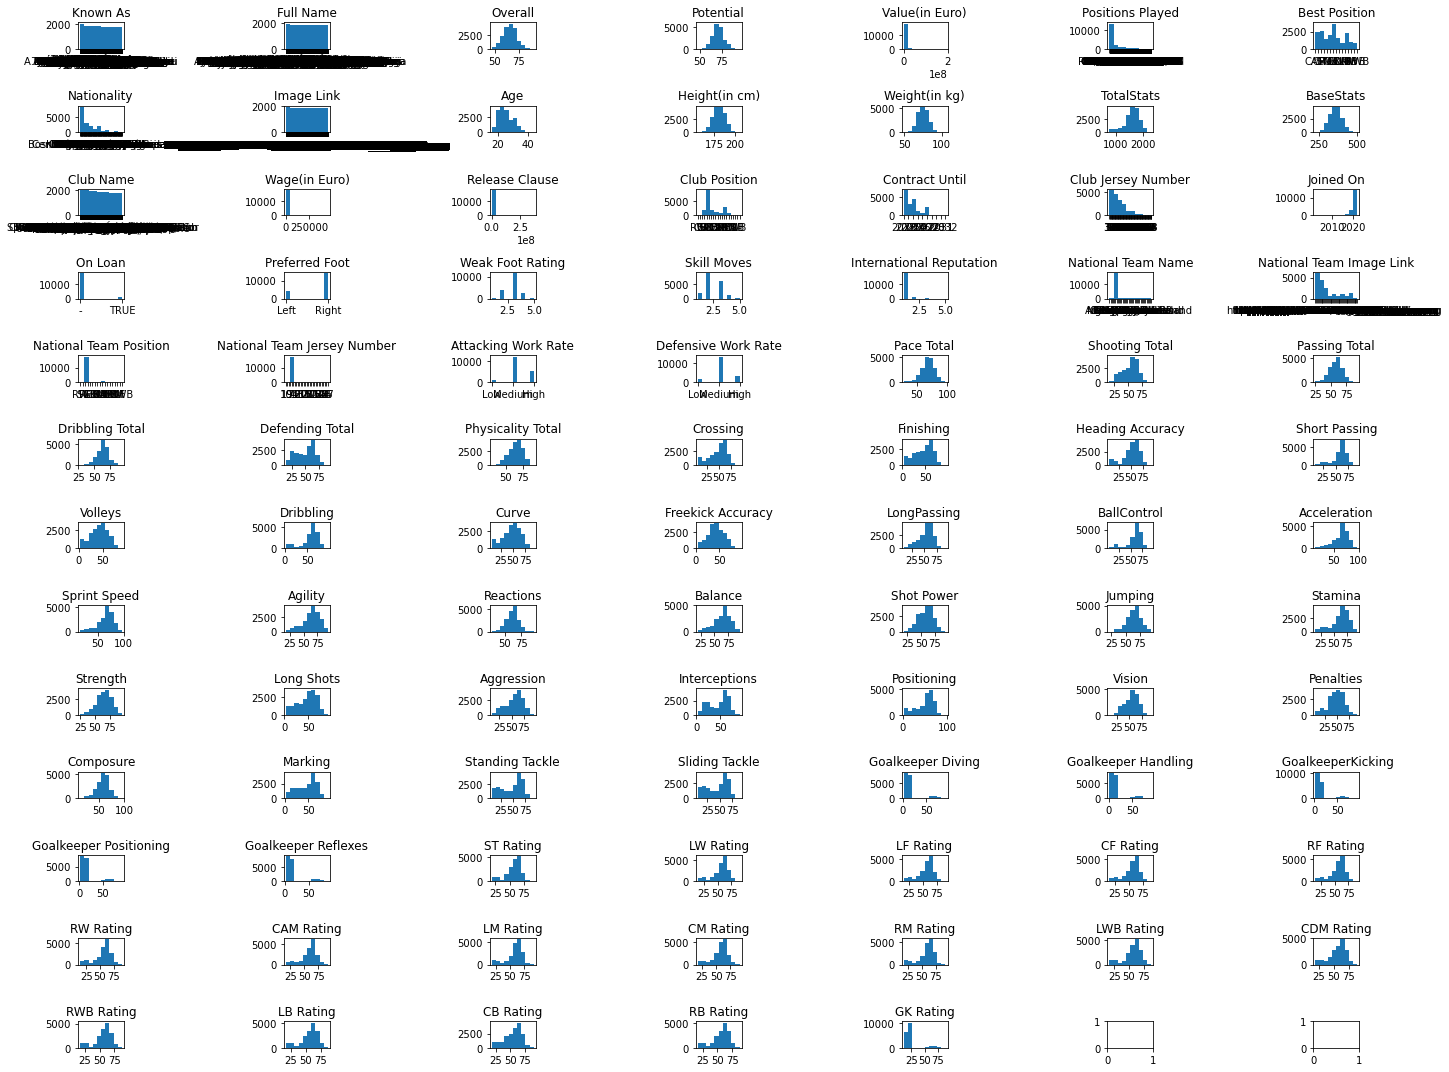

In [5]:
# Read in the FIFA dataset
df = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Create a figure with subplots for each variable
num_cols = len(df.columns)
num_rows = (num_cols - 1) // 7 + 1
fig, axs = plt.subplots(nrows=num_rows, ncols=7, figsize=(20, 15))

# Flatten the array of subplots
axs = axs.flatten()

# Loop through each variable and plot a histogram
for i, col in enumerate(df.columns):
    axs[i].hist(df[col])
    axs[i].set_title(col)

# Add spacing between subplots
plt.tight_layout()

# Show the chart
plt.show()

# Heatmap 

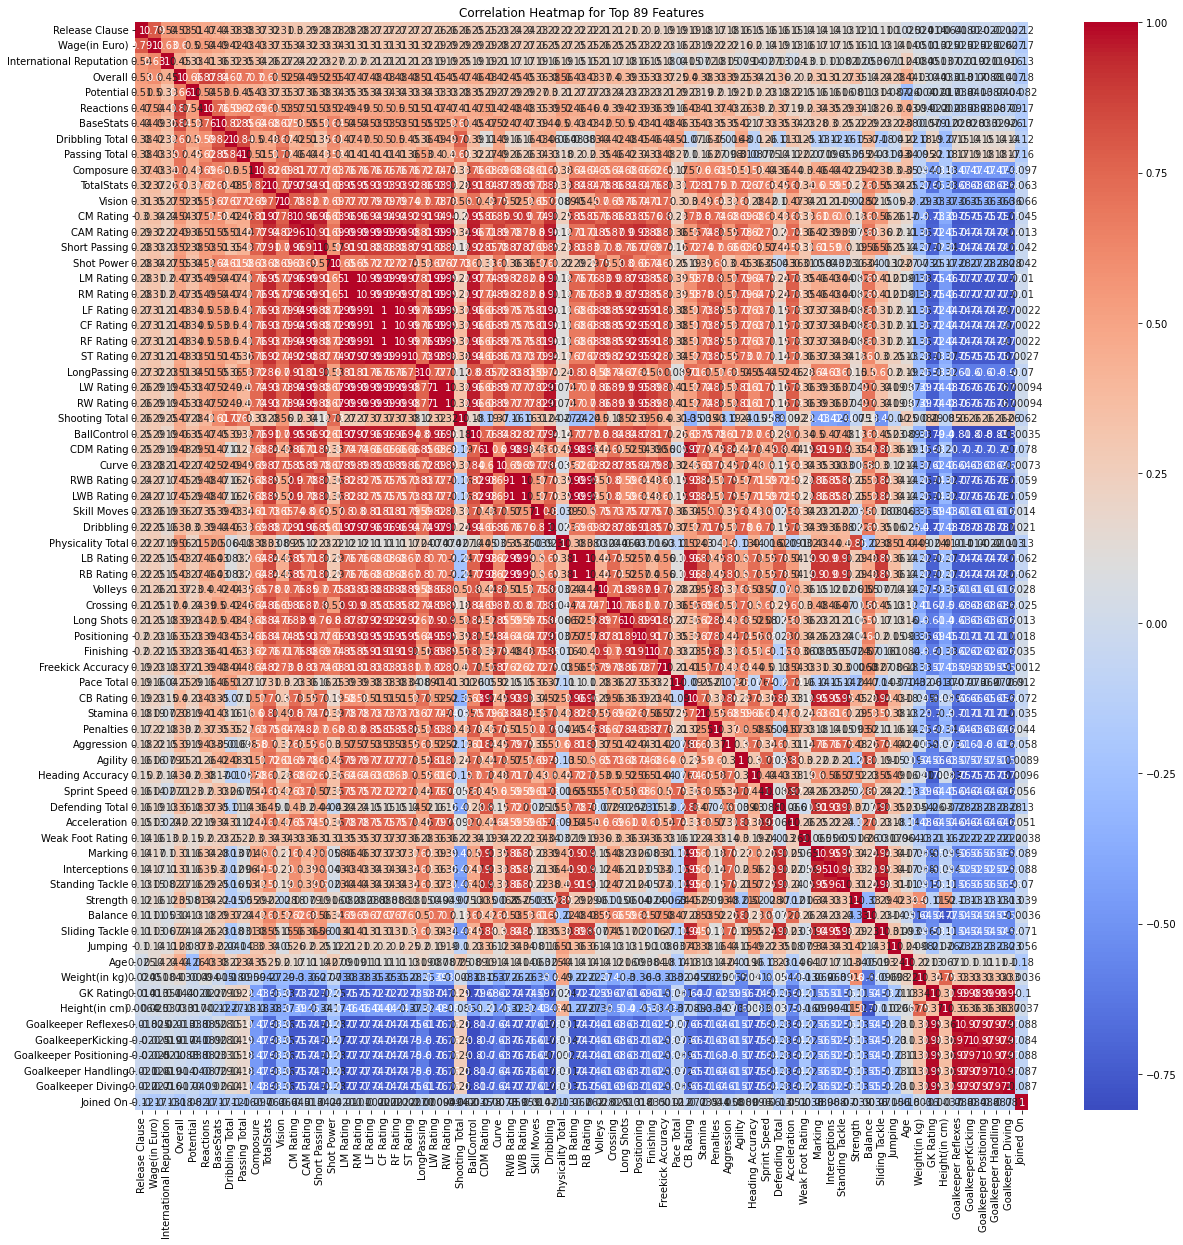

In [6]:
# Load the Fifa players dataset
fifa_data = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Create a correlation matrix
corr_matrix = fifa_data.corr()

# Select the column with the dependent variable
dep_var_corr = corr_matrix['Value(in Euro)']

# Sort the correlations in descending order
dep_var_corr = dep_var_corr.sort_values(ascending=False)

# Select the top n features with highest correlations
n = 89
top_corr_features = dep_var_corr.index[1:n+1]

# Create a heatmap of the correlations
plt.figure(figsize=(20,20))
sns.heatmap(fifa_data[top_corr_features].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Top {} Features'.format(n))
plt.show()

# Correlation Matrix

In [7]:
df = pd.DataFrame(data)

# Compute the correlation matrix
corr_matrix1 = df.corr()

# Print the correlation matrix
print(corr_matrix1)

                 Overall  Potential  Value(in Euro)       Age  Height(in cm)  \
Overall         1.000000   0.667706        0.561440  0.447173       0.033088   
Potential       0.667706   1.000000        0.541454 -0.250087       0.015060   
Value(in Euro)  0.561440   0.541454        1.000000  0.027939       0.008725   
Age             0.447173  -0.250087        0.027939  1.000000       0.069574   
Height(in cm)   0.033088   0.015060        0.008725  0.069574       1.000000   
...                  ...        ...             ...       ...            ...   
RWB Rating      0.455764   0.296811        0.252935  0.143730      -0.321877   
LB Rating       0.432548   0.276699        0.235353  0.143890      -0.272793   
CB Rating       0.405150   0.234747        0.203319  0.183778      -0.090631   
RB Rating       0.432548   0.276699        0.235353  0.143890      -0.272793   
GK Rating       0.042824   0.002065        0.012067  0.129958       0.371928   

                Weight(in kg)  TotalSta

In [8]:
# Select values between 0.2 and 0.7
corr_values = corr_matrix[(corr_matrix >= 0.3) & (corr_matrix < 0.7)].values

# Print the selected values
# Create a new DataFrame with the selected values

selected_corr = pd.DataFrame(corr_values, columns=corr_matrix1.columns, index=corr_matrix1.index)

    # Print the new DataFrame
print(selected_corr)

                 Overall  Potential  Value(in Euro)       Age  Height(in cm)  \
Overall              NaN   0.660630        0.561642  0.442369            NaN   
Potential       0.660630        NaN        0.532835       NaN            NaN   
Value(in Euro)  0.561642   0.532835             NaN       NaN            NaN   
Age             0.442369        NaN             NaN       NaN            NaN   
Height(in cm)        NaN        NaN             NaN       NaN            NaN   
...                  ...        ...             ...       ...            ...   
RWB Rating      0.451583        NaN             NaN       NaN            NaN   
LB Rating       0.428254        NaN             NaN       NaN            NaN   
CB Rating       0.400783        NaN             NaN       NaN            NaN   
RB Rating       0.428254        NaN             NaN       NaN            NaN   
GK Rating            NaN        NaN             NaN       NaN       0.369929   

                Weight(in kg)  TotalSta

In [9]:
num_vars = selected_corr.shape[1]
print(f"There are {num_vars} variables in the dataframe.")

There are 71 variables in the dataframe.


# Heatmap for selected correlations

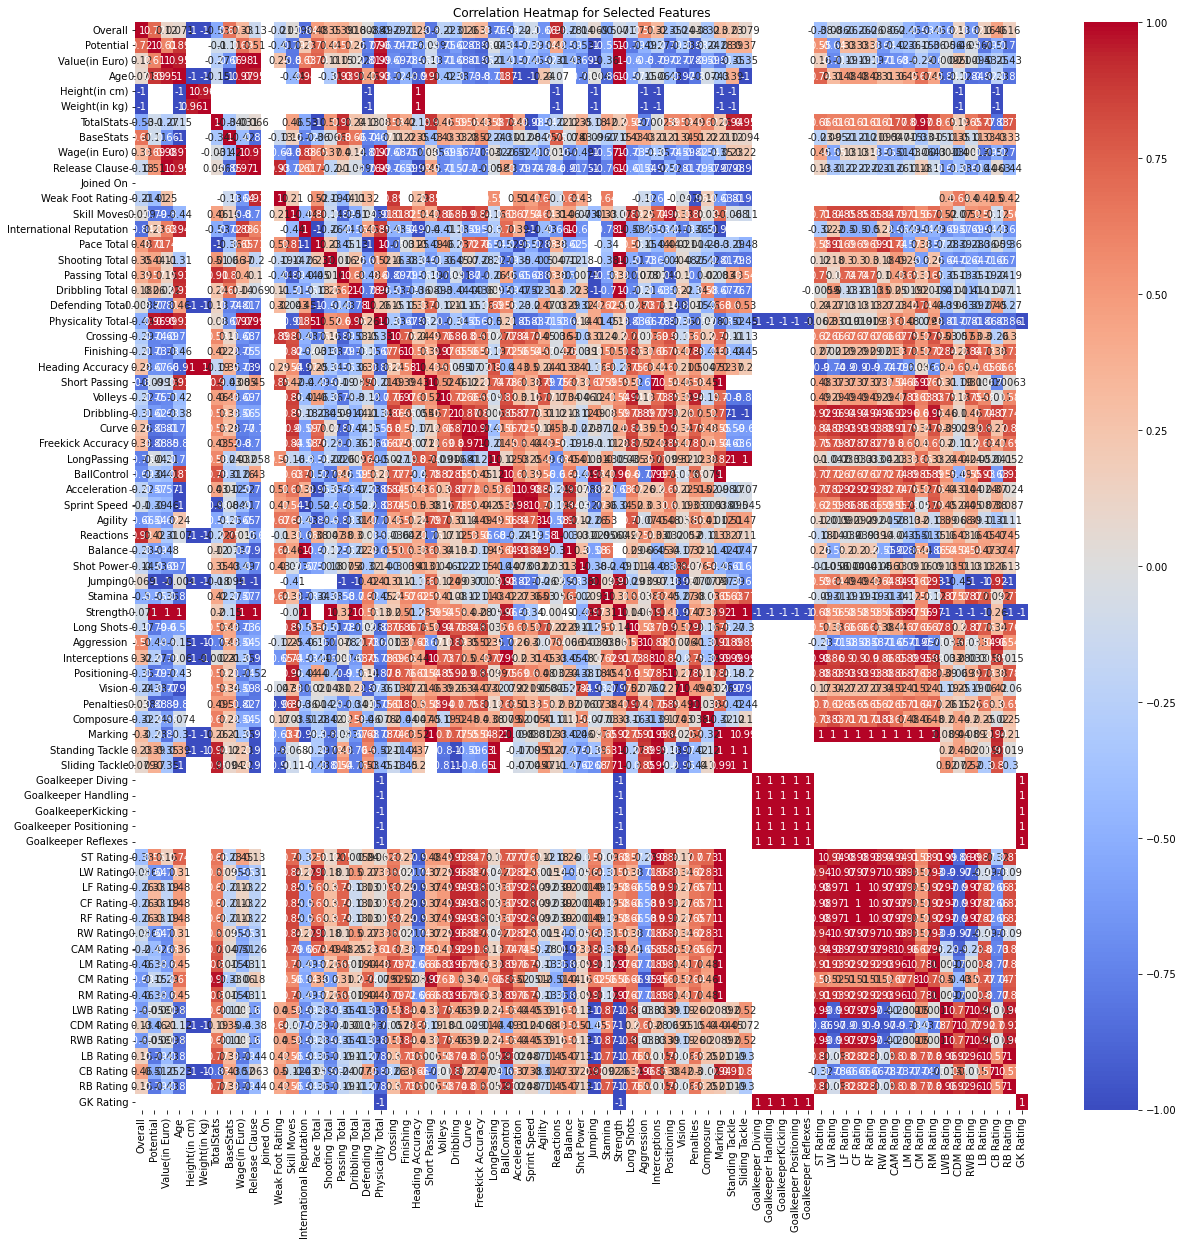

In [10]:
# Compute the correlation matrix for the selected correlations
corr_matrix_selected = selected_corr.corr()

# Create a heatmap of the correlations
plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix_selected, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Selected Features')
plt.show()

# Heatmap of Top 40 correlations

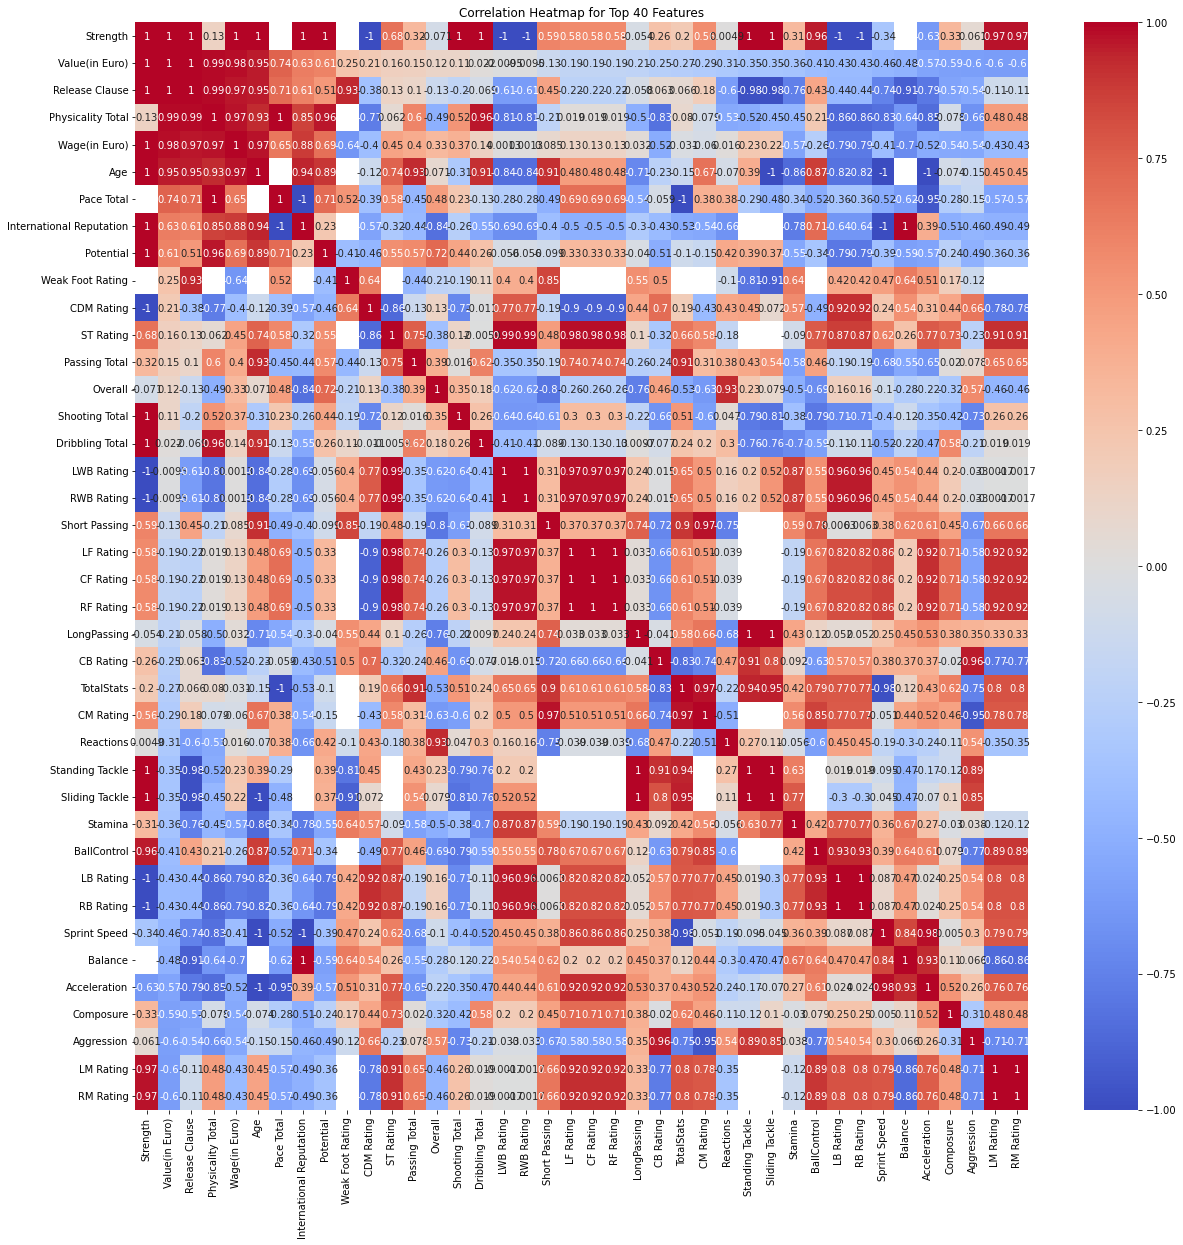

In [11]:
# Compute the correlation matrix for the selected correlations
#corr_matrix_selected = selected_corr.corr()

# Select the top 40 features with highest correlations
n = 40
top_corr_features = corr_matrix_selected.nlargest(n, 'Value(in Euro)').index

# Create a heatmap of the correlations
plt.figure(figsize=(20,20))
sns.heatmap(corr_matrix_selected.loc[top_corr_features, top_corr_features], annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Top {} Features'.format(n))
plt.show()

# P-values

In [12]:
import statsmodels.api as sm
# Define the features (independent variables)
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_data['Value(in Euro)']

# Add a constant column to the features
features_with_constant = sm.add_constant(fifa_data[features])

# Fit a linear regression model
model = sm.OLS(target, features_with_constant)
results = model.fit()

# Get the p-values for each feature
p_values = results.pvalues

# Print the p-values
print("P-values:")
print(p_values)

/Users/akshayraghunath/opt/anaconda3/lib/python3.9/site-packages/statsmodels/tsa/tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)


P-values:
const                        9.854004e-16
Strength                     3.301967e-02
Release Clause               0.000000e+00
Physicality Total            7.854686e-02
Wage(in Euro)               1.465966e-290
Age                          2.435846e-55
Pace Total                   2.487393e-01
International Reputation     6.231654e-94
Potential                    9.837097e-10
Weak Foot Rating             7.575745e-01
CDM Rating                   2.611089e-01
ST Rating                    3.183921e-01
Passing Total                1.332406e-02
Overall                      4.714249e-27
Shooting Total               8.582359e-01
Dribbling Total              4.517619e-01
LWB Rating                   6.548737e-01
RWB Rating                   6.548737e-01
Short Passing                3.909260e-01
LF Rating                    5.310583e-01
CF Rating                    5.310583e-01
RF Rating                    5.310583e-01
LongPassing                  7.671712e-01
CB Rating               

## Linear Regression

In [13]:
# Load FIFA dataset
fifa_data = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Select relevant features and target variable
X = fifa_data[['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']]
y = fifa_data['Value(in Euro)']
y_threshold = np.median(fifa_data['Value(in Euro)'])
y = np.where(fifa_data['Value(in Euro)'] >= y_threshold, 1, 0)

# Calculate correlation matrix and select columns with correlation between 0.2 and 0.7
#corr_matrix = fifa_data.corr()
#selected_features = corr_matrix[(corr_matrix['Value'] >= 0.2) & (corr_matrix['Value'] <= 0.7)].index.tolist()

# Refit feature matrix with selected columns
#X = fifa_data[selected_features]

# Split data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Fit linear regression model to training data
model = LinearRegression()
model.fit(X_train, y_train)

# Predict transfer values for test set
y_pred = model.predict(X_test)

# Evaluate model performance using mean squared error and R-squared
from sklearn.metrics import r2_score
r2 = r2_score(y_test, y_pred)
print(f"R-squared: {r2:.2f}")

# Calculate false positive rate, true positive rate, and thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_pred)



R-squared: 0.62


## Random Forest

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1512000. 1927000. 2120000. ... 2576000. 2373000.  505750.]
Mean Absolute Error: 153144.92465210354
F1 score: 0.8421052631578948


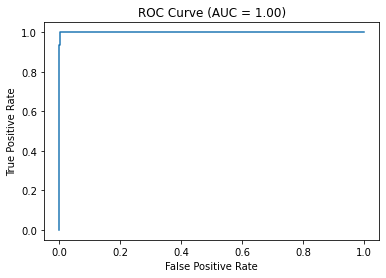

In [14]:
# Load FIFA dataset
fifa_datarg = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
X = fifa_datarg[['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']]
y = fifa_datarg['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a random forest model and fit it to the training data
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Predict the target variable for the test data
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)
# Compute the mean absolute error
mae = mean_absolute_error(y_test, y_pred)

# Convert the predicted values to binary classification labels
y_pred_binary = [1 if y >= 50_000_000 else 0 for y in y_pred]

# Convert the true values to binary classification labels
y_test_binary = [1 if y >= 50_000_000 else 0 for y in y_test]

# Compute the F1 score for the binary classification labels
f1 = f1_score(y_test_binary, y_pred_binary)

# Print the MAE and F1 score
print("Mean Absolute Error:", mae)
print("F1 score:", f1)

# Compute the false positive rate, true positive rate, and thresholds for the ROC curve
fpr, tpr, thresholds = roc_curve(y_test_binary, y_pred)

# Compute the AUC score for the ROC curve
auc = roc_auc_score(y_test_binary, y_pred)

# Plot the ROC curve
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (AUC = {:.2f})'.format(auc))
plt.show()

## Gradient Boosting

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1504517.0137987  2030661.59969703 2335784.73667751 ... 2207701.11521669
 2355900.85306097  587257.56351547]
MAE: 234442.8258331384
F1 score: 0.8571428571428572


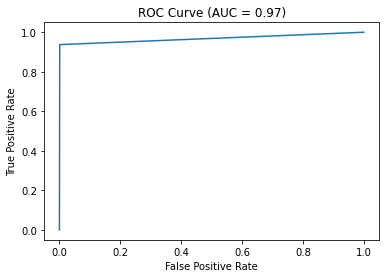

In [15]:
# Load FIFA dataset
fifa_datagbr = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
X = fifa_datagbr[['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']]
y = fifa_datagbr['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a gradient boosting model and fit it to the training data
model = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42)
model.fit(X_train, y_train)

# Predict the target variable for the test data
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)
# Compute the Mean Absolute Error (MAE) for the predictions
mae = np.mean(np.abs(y_test - y_pred))

# Print the MAE and F1 score
print("MAE:", mae)
print("F1 score:", f1_score(y_test >= 50_000_000, y_pred >= 50_000_000))

# Calculate false positive rate, true positive rate, and thresholds
fpr, tpr, thresholds = roc_curve(y_test >= 50_000_000, y_pred >= 50_000_000)

# Calculate AUC score
auc = roc_auc_score(y_test >= 50_000_000, y_pred >= 50_000_000)

# Plot ROC curve
# import matplotlib.pyplot as plt
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (AUC = {:.2f})'.format(auc))
plt.show()

## Multilayer Perceptron

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1820706.29930502 1937693.12957903 2341284.64074464 ... 2089819.04001694
 2573396.59953174  469223.74139629]
Mean absolute error: 370899.7826416786
F1 score: 0.9090909090909091


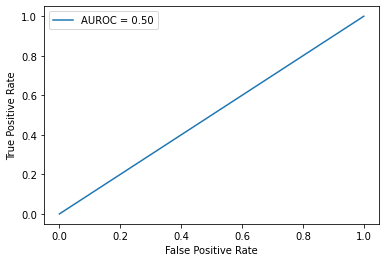

In [16]:
# Load the dataset
fifa_datamlp = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
X = fifa_datamlp[['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']]
y = fifa_datamlp['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create a multilayer perceptron model and fit it to the training data
model = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', random_state=42)
model.fit(X_train, y_train)

# Predict the target variable for the test data
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)

# Compute the mean absolute error between the predicted and true values
mae = mean_absolute_error(y_test, y_pred)

# Convert the predicted values to probabilities using the sigmoid function
y_pred_proba = 1 / (1 + np.exp(-y_pred))

# Compute the AUC-ROC score
auc_roc = roc_auc_score(y_test >= 50_000_000, y_pred_proba)

# Compute the false positive rate and true positive rate
fpr, tpr, _ = roc_curve(y_test >= 50_000_000, y_pred_proba)

# Convert the predicted values to binary classification labels
y_pred_binary = [1 if y >= 50_000_000 else 0 for y in y_pred]

# Convert the true values to binary classification labels
y_test_binary = [1 if y >= 50_000_000 else 0 for y in y_test]

# Compute the F1 score for the binary classification labels
f1 = f1_score(y_test_binary, y_pred_binary)

# Print the mean absolute error and F1 score
print("Mean absolute error:", mae)
print("F1 score:", f1)

# Plot the ROC curve
plt.plot(fpr, tpr, label='AUROC = %0.2f' % auc_roc)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## K-Nearest Neighbors

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1580000. 1940000. 2800000. ... 2360000. 2300000.  540000.]
F1 Score: 0.9472817133443163
MAE: 315954.4218446602


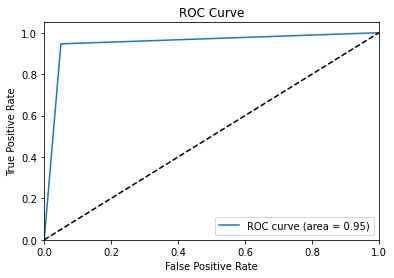

In [17]:
# Load the dataset
fifa_dataknn = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_dataknn['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(fifa_dataknn[features], target, test_size=0.2, random_state=42)

# Train the KNN model
model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train, y_train)

# Evaluate the model on the testing set
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in y_pred]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)
mae = mean_absolute_error(y_test, y_pred)

print('F1 Score:', f1)
print('MAE:', mae)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_class, y_pred_class)

# Calculate AUC
roc_auc = roc_auc_score(y_test_class, y_pred_class)

# Plot ROC curve
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--') # random predictions curve
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

## XGBoost

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1512296.4  1930215.1  2245602.5  ... 2507234.5  2276985.5   523083.38]
F1 Score: 0.9766536964980543
MAE: 160616.6916701431
Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1512296.4  1930215.1  2245602.5  ... 2507234.5  2276985.5   523083.38]
F1 Score: 0.9766536964980543
MAE: 160616.6916701431


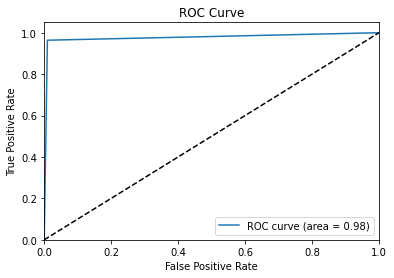

In [18]:
# Load the dataset
fifa_dataxgb = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_dataxgb['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(fifa_dataxgb[features], target, test_size=0.2, random_state=42)

# Train the XGBoost model
model = xgb.XGBRegressor()
model.fit(X_train, y_train)

# Evaluate the model on the testing set
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in y_pred]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)

# Calculate mean absolute error
mae = mean_absolute_error(y_test, y_pred)

print('F1 Score:', f1)
print('MAE:', mae)

# Convert the predicted values to binary classification labels
y_pred_binary = [1 if y >= 50_000_000 else 0 for y in y_pred]

# Convert the true values to binary classification labels
y_test_binary = [1 if y >= 50_000_000 else 0 for y in y_test]

# Calculate the false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(y_test_binary, y_pred_binary)

# Evaluate the model on the testing set
y_pred = model.predict(X_test)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", y_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in y_pred]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)
mae = mean_absolute_error(y_test, y_pred)

print('F1 Score:', f1)
print('MAE:', mae)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_class, y_pred_class)

# Calculate AUC
roc_auc = roc_auc_score(y_test_class, y_pred_class)

# Plot ROC curve
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--') # random predictions curve
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

## Hybrid (LR+RF)

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1759286.03427526 2687293.71538804 2408799.00401981 ... 2455152.57981633
 2509576.02860761  402547.98433059]
F1 Score: 0.9419776627621902
MAE: 401334.2891435375


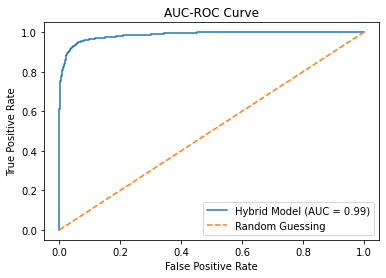

In [19]:
# Load the dataset
fifa_data = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_data['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(fifa_data[features], target, test_size=0.2, random_state=42)

# Train the linear regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Train the random forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate the models on the testing set
linear_pred = linear_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

# Combine the predictions using a weighted average
# Here, we are using a weight of 0.7 for the linear regression model and 0.3 for the random forest model
hybrid_pred = 0.7 * linear_pred + 0.3 * rf_pred
print("Actual Values:\n", y_test)
print("Predicted Values:\n", hybrid_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in hybrid_pred]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)

# Calculate MAE
mae = mean_absolute_error(y_test, hybrid_pred)

print('F1 Score:', f1)
print('MAE:', mae)

# Calculate AUC-ROC score and plot the curve
auc_roc_score = roc_auc_score(y_test_class, hybrid_pred)
fpr, tpr, thresholds = roc_curve(y_test_class, hybrid_pred)
plt.plot(fpr, tpr, label='Hybrid Model (AUC = {:.2f})'.format(auc_roc_score))
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guessing')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('AUC-ROC Curve')
plt.legend()
plt.show()

## Hybrid (XGB+MLP)

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1759286.03427526 2687293.71538804 2408799.00401981 ... 2455152.57981633
 2509576.02860761  402547.98433059]
MAE: 226500.0103929727
F1 Score: 0.954874651810585


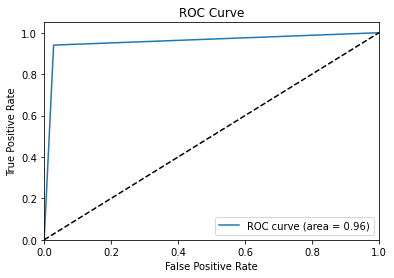

In [20]:
# Load the dataset
fifa_datahyb2 = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Define the features and target variable
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_datahyb2['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(fifa_datahyb2[features], target, test_size=0.2, random_state=42)

# Train the XGBoost model
xgb_model = XGBRegressor(n_estimators=1000, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)

# Train the MLP model
mlp_model = MLPRegressor(hidden_layer_sizes=(100,50), max_iter=1000, activation='relu', solver='adam', random_state=42)
mlp_model.fit(X_train, y_train)

# Predict using both models
y_pred_xgb = xgb_model.predict(X_test)
y_pred_mlp = mlp_model.predict(X_test)
y_pred_hybrid = np.mean([y_pred_xgb, y_pred_mlp], axis=0)
print("Actual Values:\n", y_test)
print("Predicted Values:\n", hybrid_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in y_pred_hybrid]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)

mse = mean_squared_error(y_test, y_pred_hybrid)
mae = mean_absolute_error(y_test, y_pred_hybrid)
r2 = r2_score(y_test, y_pred_hybrid)
print('MAE:', mae)
print('F1 Score:', f1)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test_class, y_pred_class)

# Calculate AUC
roc_auc = roc_auc_score(y_test_class, y_pred_class)

# Plot ROC curve
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--') # random predictions curve
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

## Hybrid (KNN+GB)

Actual Values:
 10157    1500000
3617     1900000
4894     2100000
2315     8000000
2177     5000000
          ...   
9049      725000
14757     800000
6779     2500000
3269     2300000
11602     500000
Name: Value(in Euro), Length: 3708, dtype: int64
Predicted Values:
 [1759286.03427526 2687293.71538804 2408799.00401981 ... 2455152.57981633
 2509576.02860761  402547.98433059]
F1 Score: 0.9557327467693154
MAE: 253546.66593871455


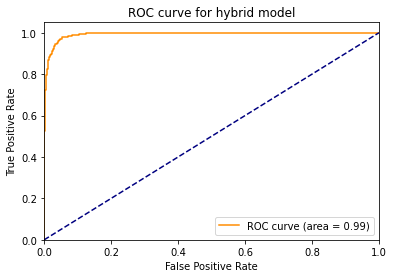

In [21]:
# Load the dataset
fifa_datahyb3 = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')
# Define the features and target variable
features = ['Strength', 'Release Clause', 'Physicality Total', 'Wage(in Euro)', 'Age', 'Pace Total', 'International Reputation', 'Potential', 'Weak Foot Rating', 'CDM Rating', 'ST Rating', 'Passing Total', 'Overall', 'Shooting Total', 'Dribbling Total', 'LWB Rating', 'RWB Rating', 'Short Passing', 'LF Rating', 'CF Rating', 'RF Rating', 'LongPassing', 'CB Rating', 'TotalStats', 'CM Rating', 'Reactions', 'Standing Tackle', 'Stamina', 'BallControl', 'LB Rating', 'RB Rating', 'Sprint Speed', 'Balance', 'Acceleration', 'Composure', 'Aggression', 'LM Rating', 'RM Rating']
target = fifa_datahyb3['Value(in Euro)']

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(fifa_datahyb3[features], target, test_size=0.2, random_state=42)

# Train the KNN model
knn_model = KNeighborsRegressor(n_neighbors=5)
knn_model.fit(X_train, y_train)

# Train the Gradient Boosting model
gb_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_model.fit(X_train, y_train)

# Evaluate the hybrid model on the testing set
y_pred_knn = knn_model.predict(X_test)
y_pred_gb = gb_model.predict(X_test)

# Combine the predictions from the two models
y_pred = (y_pred_knn + y_pred_gb) / 2
print("Actual Values:\n", y_test)
print("Predicted Values:\n", hybrid_pred)

# Calculate F1 score using a threshold value of 1 million euros
threshold = 1000000
y_pred_class = [1 if y >= threshold else 0 for y in y_pred]
y_test_class = [1 if y >= threshold else 0 for y in y_test]
f1 = f1_score(y_test_class, y_pred_class)

print('F1 Score:', f1)


# Calculate MAE for hybrid model
mae = mean_absolute_error(y_test, y_pred)
print('MAE:', mae)

# Calculate ROC curve and AUC score for hybrid model
fpr, tpr, thresholds = roc_curve(y_test_class, y_pred)
roc_auc = roc_auc_score(y_test_class, y_pred)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC curve for hybrid model')
plt.legend(loc="lower right")
plt.show()

## Comparison of F1 scores for each algorithm

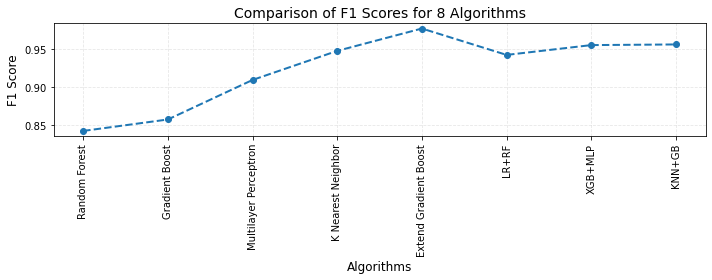

In [22]:
# F1 scores for each algorithm
f1_scores = [0.8421052631578948, 0.8571428571428572, 0.9090909090909091, 0.9472817133443163, 0.9766536964980543, 0.9419776627621902, 0.954874651810585, 0.9557327467693154]

# Names of the algorithms
algorithms = ['Random Forest', 'Gradient Boost', 'Multilayer Perceptron', 'K Nearest Neighbor', 'Extend Gradient Boost', 'LR+RF', 'XGB+MLP', 'KNN+GB']

# Create a line chart
plt.figure(figsize=(10, 4))
plt.plot(algorithms, f1_scores, marker='o', linewidth=2, color='#1f77b4', linestyle='--')

# Add labels and title
plt.xlabel('Algorithms', fontsize=12)
plt.ylabel('F1 Score', fontsize=12)
plt.title('Comparison of F1 Scores for 8 Algorithms', fontsize=14)

# Add grid lines
plt.grid(True, linestyle='--', alpha=0.7)

# Adjust tick labels font size
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# Rotate x-axis labels
plt.xticks(rotation=90)

# Customize the chart style
plt.grid(alpha=0.3)
plt.tight_layout()

# Show the chart
plt.show()

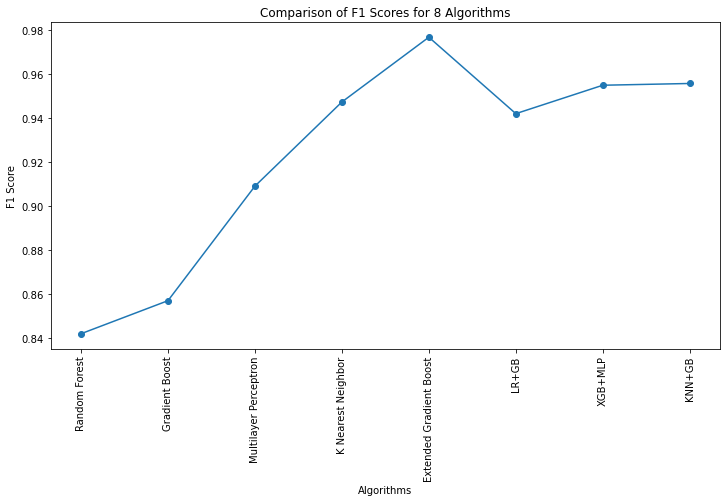

In [23]:
# F1 scores for each algorithm
f1_scores = [0.8421, 0.8571, 0.9091, 0.9473, 0.9767, 0.9420, 0.9549, 0.9557]

# Names of the algorithms
algorithms = ['Random Forest', 'Gradient Boost', 'Multilayer Perceptron', 'K Nearest Neighbor', 'Extended Gradient Boost', 'LR+GB', 'XGB+MLP', 'KNN+GB']

# Create a line chart
plt.figure(figsize=(12,6))
plt.plot(algorithms, f1_scores, marker='o')

# Add labels and title
plt.xlabel('Algorithms')
plt.ylabel('F1 Score')
plt.title('Comparison of F1 Scores for 8 Algorithms')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Show the chart
plt.show()

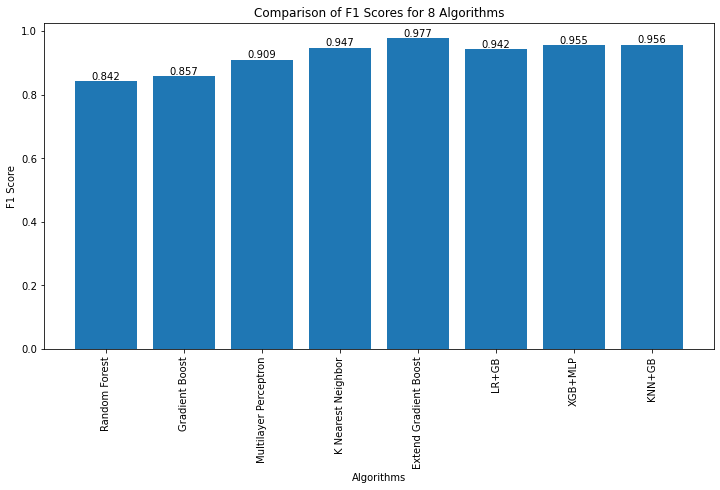

In [24]:
# F1 scores for each algorithm
f1_scores = [0.8421052631578948, 0.8571428571428572, 0.9090909090909091, 0.9472817133443163, 0.9766536964980543, 0.9419776627621902, 0.954874651810585, 0.9557327467693154]

# Names of the algorithms
algorithms = ['Random Forest', 'Gradient Boost', 'Multilayer Perceptron', 'K Nearest Neighbor', 'Extend Gradient Boost', 'LR+GB', 'XGB+MLP', 'KNN+GB']

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(algorithms, f1_scores)

# Add labels and title
plt.xlabel('Algorithms')
plt.ylabel('F1 Score')
plt.title('Comparison of F1 Scores for 8 Algorithms')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Add data labels to the bars
for i, v in enumerate(f1_scores):
    plt.text(i, v, str(round(v, 3)), ha='center', va='bottom')

# Show the chart
plt.show()

## Comparison of Mean Absolute Error for each Algorithm

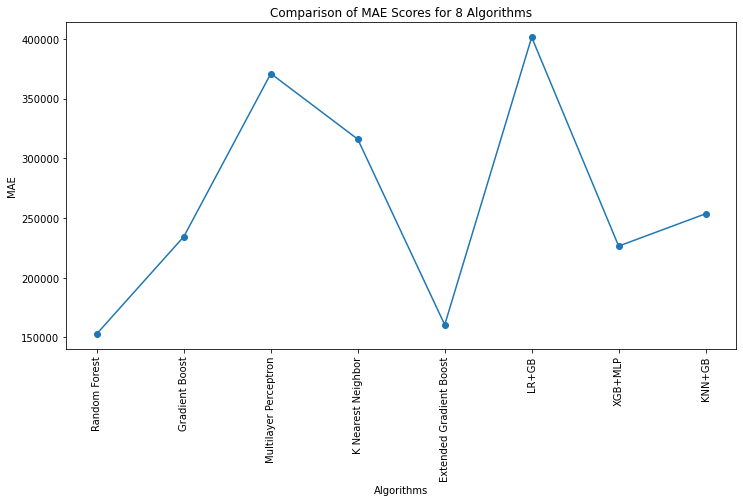

In [25]:
# MAE for each algorithm
MAE = [153144, 234442, 370899, 315954, 160616, 401334, 226500, 253546]

# Names of the algorithms
algorithms = ['Random Forest', 'Gradient Boost', 'Multilayer Perceptron', 'K Nearest Neighbor', 'Extended Gradient Boost', 'LR+GB', 'XGB+MLP', 'KNN+GB']

# Create a line chart
plt.figure(figsize=(12,6))
plt.plot(algorithms, MAE, marker='o')

# Add labels and title
plt.xlabel('Algorithms')
plt.ylabel('MAE')
plt.title('Comparison of MAE Scores for 8 Algorithms')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Show the chart
plt.show()

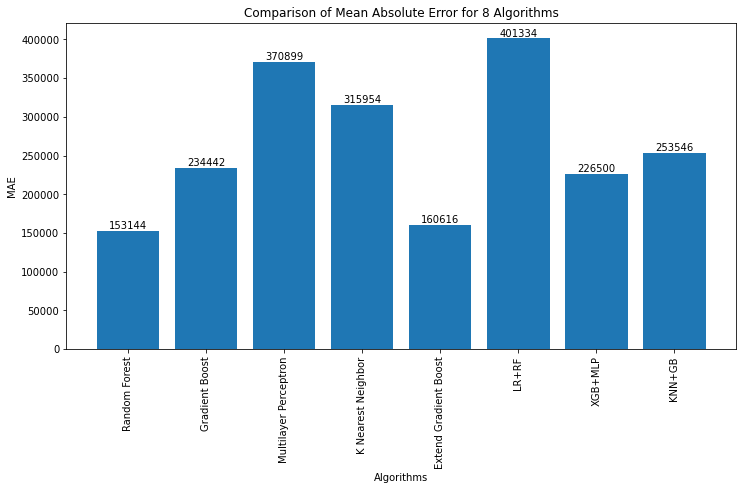

In [26]:
# MAE for each algorithm
MAE = [153144, 234442, 370899, 315954, 160616, 401334, 226500, 253546]

# Names of the algorithms
algorithms = ['Random Forest', 'Gradient Boost', 'Multilayer Perceptron', 'K Nearest Neighbor', 'Extend Gradient Boost', 'LR+RF', 'XGB+MLP', 'KNN+GB']

# Create a bar chart
plt.figure(figsize=(12, 6))
plt.bar(algorithms, MAE)

# Add labels and title
plt.xlabel('Algorithms')
plt.ylabel('MAE')
plt.title('Comparison of Mean Absolute Error for 8 Algorithms')

# Rotate the x-axis labels for better readability
plt.xticks(rotation=90)

# Add data labels to the bars
for i, v in enumerate(MAE):
    plt.text(i, v, str(round(v, 3)), ha='center', va='bottom')

# Show the chart
plt.show()

# Visualisations

### Histogram of Overall Ratings

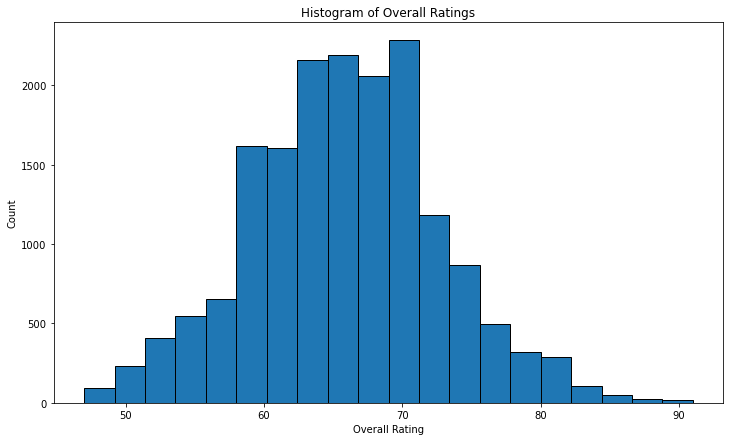

In [27]:
# Plot a histogram of Overall Ratings
plt.figure(figsize=(12,7))
plt.hist(data['Overall'], bins=20, edgecolor='black')
plt.xlabel('Overall Rating')
plt.ylabel('Count')
plt.title('Histogram of Overall Ratings')
plt.show()

### Histogram of Age

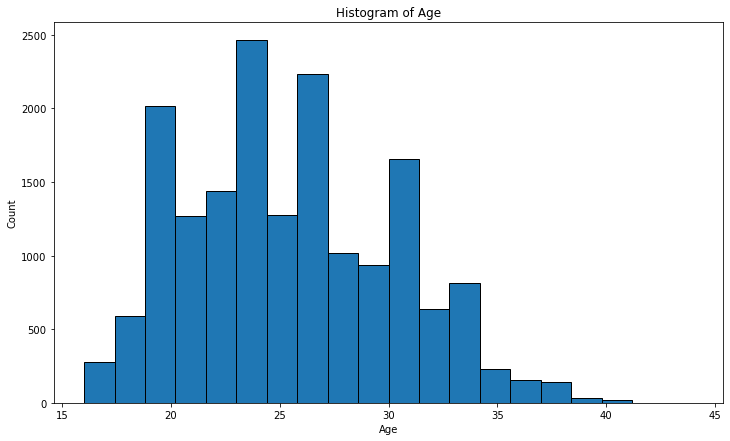

In [28]:
# Plot a histogram of Age
plt.figure(figsize=(12, 7))
plt.hist(data['Age'], bins=20, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Count')
plt.title('Histogram of Age')
plt.show()

### Scatter plot of Overall Rating vs Market Value

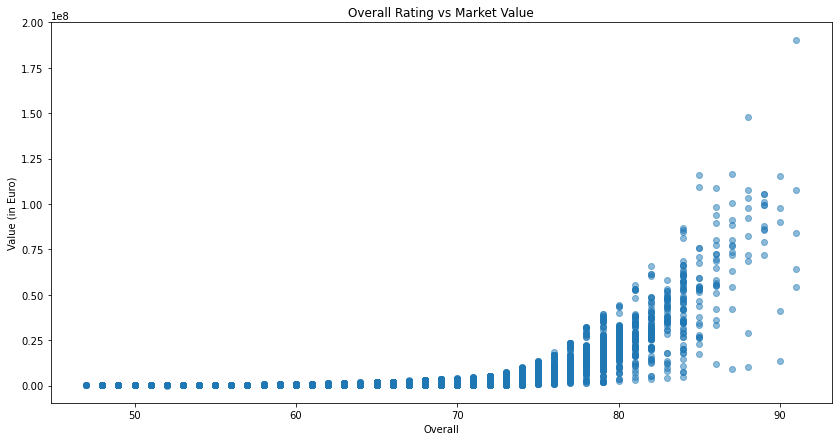

In [29]:
# Create a scatter plot of Overall Rating vs Market Value
plt.figure(figsize=(14, 7))
plt.scatter(data['Overall'], data['Value(in Euro)'], alpha=0.5)
plt.xlabel('Overall')
plt.ylabel('Value (in Euro)')
plt.title('Overall Rating vs Market Value')
plt.show()

### Scatter plot of Age vs Market Value

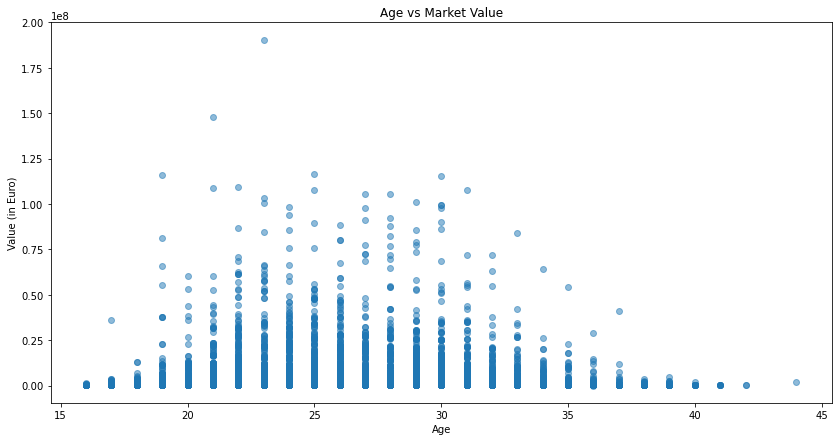

In [30]:
# Create a scatter plot of Age vs Market Value
plt.figure(figsize=(14, 7))
plt.scatter(data['Age'], data['Value(in Euro)'], alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Value (in Euro)')
plt.title('Age vs Market Value')
plt.show()

### Scatter plot of Age vs Overall Rating

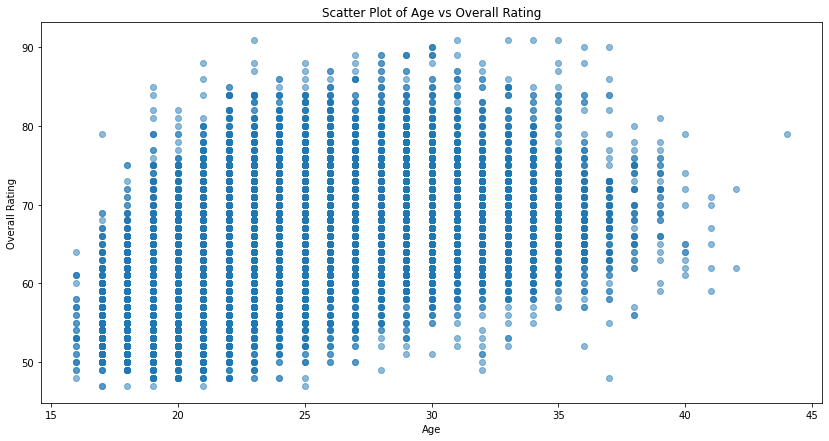

In [31]:
# Create a scatter plot of Age vs Overall rating
plt.figure(figsize=(14, 7))
plt.scatter(data['Age'], data['Overall'], alpha=0.5)
plt.xlabel('Age')
plt.ylabel('Overall Rating')
plt.title('Scatter Plot of Age vs Overall Rating')
plt.show()

### Line Graph of Player Position and Transfer Value

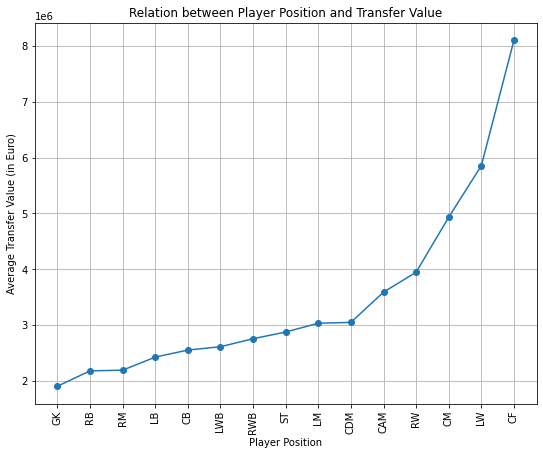

In [32]:
# Group the dataset by player position and calculate average transfer value
position_avg_value = data.groupby('Best Position')['Value(in Euro)'].mean().reset_index()

# Sort the positions based on the average transfer value
position_avg_value = position_avg_value.sort_values('Value(in Euro)')

# Create a line graph
plt.figure(figsize=(9, 7))
plt.plot(position_avg_value['Best Position'], position_avg_value['Value(in Euro)'], marker='o')
plt.xlabel('Player Position')
plt.ylabel('Average Transfer Value (in Euro)')
plt.title('Relation between Player Position and Transfer Value')
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability
plt.grid(True)
plt.show()

### Scatter Plot of Release Clause vs Transfer Value

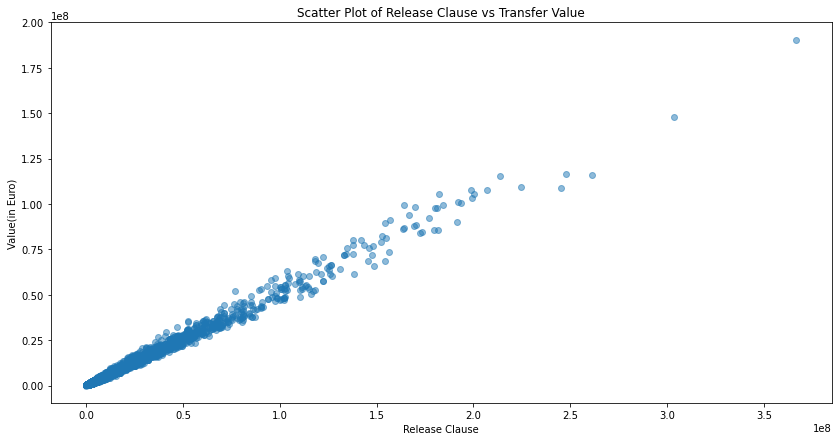

In [33]:
# Create a scatter plot of Release clause vs Transfer Value
plt.figure(figsize=(14, 7))
plt.scatter(data['Release Clause'], data['Value(in Euro)'], alpha=0.5)
plt.xlabel('Release Clause')
plt.ylabel('Value(in Euro)')
plt.title('Scatter Plot of Release Clause vs Transfer Value')
plt.show()

### Scatter plot of Wages vs Transfer Value

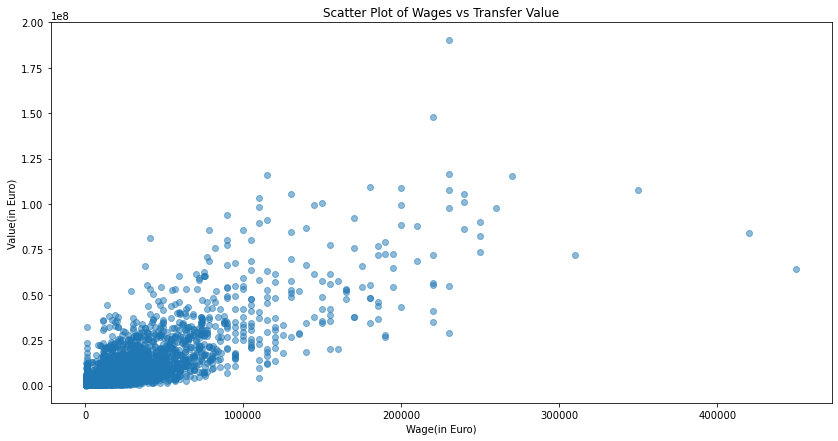

In [34]:
# Create a scatter plot of Wages vs Transfer Value
plt.figure(figsize=(14, 7))
plt.scatter(data['Wage(in Euro)'], data['Value(in Euro)'], alpha=0.5)
plt.xlabel('Wage(in Euro)')
plt.ylabel('Value(in Euro)')
plt.title('Scatter Plot of Wages vs Transfer Value')
plt.show()

### Bar Graph showing the Clubs from Oldest to Youngest in terms of Average Age of players

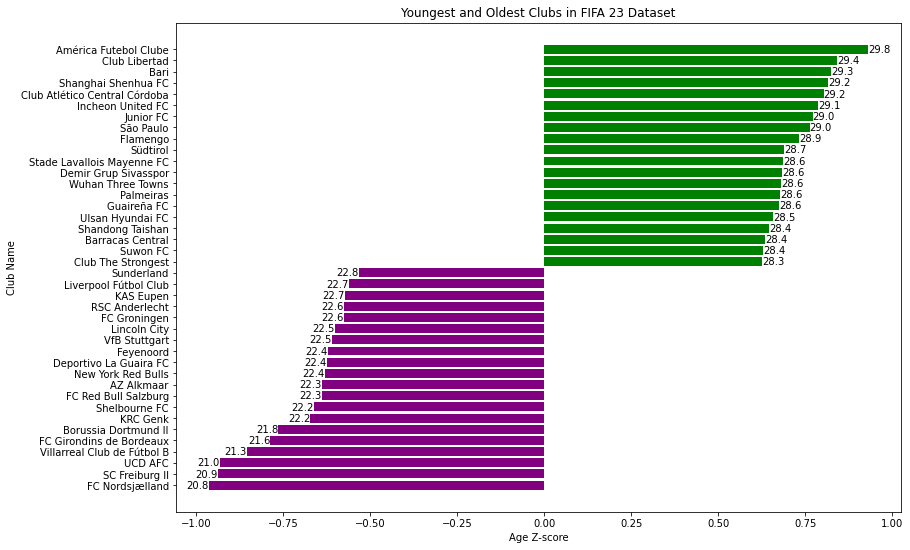

In [35]:
# Calculate standard deviation of Age
age_sd = np.std(data['Age'])

# Group by Club and calculate average Age
club_avg_age = data.groupby('Club Name')['Age'].mean().reset_index()

# Calculate Age Z-score
club_avg_age['AgeZ_score'] = (club_avg_age['Age'] - np.mean(data['Age'])) / age_sd

# Create AgeType column based on AgeZ_score
club_avg_age['AgeType'] = np.where(club_avg_age['AgeZ_score'] < 0, 'Below', 'Above')

# Sort the dataframe by AgeZ_score in descending order
club_avg_age = club_avg_age.sort_values('AgeZ_score', ascending=False)

# Select the top 20 and bottom 20 rows
top_20_oldest = club_avg_age.head(20)
bottom_20_youngest = club_avg_age.tail(20)

# Combine the top 20 and bottom 20 rows
combined_df = pd.concat([top_20_oldest, bottom_20_youngest])

# Plot the bar graph
plt.figure(figsize=(13, 9))
bars = plt.barh(combined_df['Club Name'], combined_df['AgeZ_score'], color=np.where(combined_df['AgeZ_score'] < 0, 'purple', 'green'))
plt.xlabel('Age Z-score')
plt.ylabel('Club Name')
plt.title('Youngest and Oldest Clubs in FIFA 23 Dataset')
plt.gca().invert_yaxis()  # Invert y-axis to show highest at the top

# Add average age labels at the end of each bar
for bar, age, z_score in zip(bars, combined_df['Age'], combined_df['AgeZ_score']):
    if z_score < 0:
        plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f'{age:.1f}', ha='right', va='center')
    else:
        plt.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f'{age:.1f}', ha='left', va='center')

plt.show()

# A case study on LIVERPOOL FC

In [36]:
# Case study LIVERPOOL FC

'''Liverpool FC need potential players to regain their form especially in midfield position. 
Their players like Oxlade, Firmino and Keita are decided not to sign new contract.
They also need addition in the back four as well.
Here we are figure out the best fit for different position for Liverpool FC according to market condition.'''

#Alex Oxlade Chamberlain Replacement
FIFA23 = pd.read_csv('/Users/akshayraghunath/Downloads/Fifa 23 Players Data copy.csv')

# Subset players that meet the requirements
posible_oxlade_liverpool = FIFA23[(FIFA23['Age'] < 25) & (FIFA23['Overall'] > 75) & (FIFA23['Wage(in Euro)'] < 300000) & (FIFA23['Value(in Euro)'] < 80000000) & (FIFA23['Release Clause'] < 40000000) & ((FIFA23['Positions Played'] == 'CAM') | (FIFA23['Positions Played'] == 'CM'))]

# Find potential replacements for Oxlade
oxlade_chamberlain_replacement = posible_oxlade_liverpool.iloc[0] if len(posible_oxlade_liverpool) > 0 else None

# Combine the replacements into a single DataFrame
replacements = [r for r in [oxlade_chamberlain_replacement] if r is not None]
liverpool_oxlade_replacements = oxlade_chamberlain_replacement if oxlade_chamberlain_replacement is not None else pd.DataFrame()

# Print the replacement
print("Alex Oxlade Chemberlane Replacement:",liverpool_oxlade_replacements)

Alex Oxlade Chemberlane Replacement: Known As               Brahim
Full Name         Brahim Díaz
Overall                    78
Potential                  86
Value(in Euro)       31500000
                     ...     
RWB Rating                 59
LB Rating                  53
CB Rating                  42
RB Rating                  53
GK Rating                  19
Name: 815, Length: 89, dtype: object


In [37]:
# Filter for possible replacements for Firmino
possible_firmino_liverpool = FIFA23[(FIFA23['Age'] < 29) & (FIFA23['Overall'] > 75) & (FIFA23['Wage(in Euro)'] < 150000) & (FIFA23['Value(in Euro)'] < 80000000) & (FIFA23['Release Clause'] < 65000000) & ((FIFA23['Positions Played'] == 'CF') | (FIFA23['Positions Played'] == 'ST'))]

# Select the first potential replacement (if any)
firmino_replacement = possible_firmino_liverpool.iloc[0] if len(possible_firmino_liverpool) > 0 else None

# Remove any None values from the list of replacements
replacements1 = [r for r in [firmino_replacement] if r is not None]

# Print out the result
liverpool_firmino_replacements = firmino_replacement if firmino_replacement is not None else pd.DataFrame()
print("Roberto Firmino Replacement :",liverpool_firmino_replacements)

Roberto Firmino Replacement : Known As                 S. Haller
Full Name         Sébastien Haller
Overall                         82
Potential                       82
Value(in Euro)            31000000
                        ...       
RWB Rating                      63
LB Rating                       63
CB Rating                       67
RB Rating                       63
GK Rating                       18
Name: 219, Length: 89, dtype: object


In [38]:
#James Milner Replacement

# Subset players that meet the requirements
posible_milner_liverpool = FIFA23[(FIFA23['Age'] < 32) & (FIFA23['Overall'] > 65) & (FIFA23['Wage(in Euro)'] < 80000) & (FIFA23['Value(in Euro)'] < 8000000) & (FIFA23['Release Clause'] < 10000000) & ((FIFA23['Positions Played'] == 'CDM') | (FIFA23['Positions Played'] == 'CM'))]

# Find potential replacements for James Milner
milner_replacement = posible_milner_liverpool.iloc[0] if len(posible_milner_liverpool) > 0 else None

# Combine the replacements into a single DataFrame
replacements2 = [r for r in [milner_replacement] if r is not None]
liverpool_milner_replacements = milner_replacement if milner_replacement is not None else pd.DataFrame()

# Print the replacement
print("James Milner Replacement:",liverpool_milner_replacements)

James Milner Replacement: Known As              R. Falk
Full Name         Rasmus Falk
Overall                    76
Potential                  76
Value(in Euro)        7000000
                     ...     
RWB Rating                 76
LB Rating                  75
CB Rating                  70
RB Rating                  75
GK Rating                  20
Name: 1169, Length: 89, dtype: object


In [39]:
#Naby Keita Replacement
# Subset players that meet the requirements
posible_keita_liverpool = FIFA23[(FIFA23['Age'] < 24) & (FIFA23['Overall'] > 80) & (FIFA23['Wage(in Euro)'] < 1800000) & (FIFA23['Value(in Euro)'] < 100000000) & (FIFA23['Release Clause'] < 190000000) & ((FIFA23['Positions Played'] == 'CDM') | (FIFA23['Positions Played'] == 'CM'))]

# Find potential replacements for Naby Keita
keita_replacement = posible_keita_liverpool.iloc[0] if len(posible_keita_liverpool) > 0 else None

# Combine the replacements into a single DataFrame
replacements3 = [r for r in [keita_replacement] if r is not None]
liverpool_keita_replacements = keita_replacement if keita_replacement is not None else pd.DataFrame()

# Print the replacement
print("Naby Keita Replacement:",liverpool_keita_replacements)

Naby Keita Replacement: Known As              D. Rice
Full Name         Declan Rice
Overall                    84
Potential                  87
Value(in Euro)       52000000
                     ...     
RWB Rating                 80
LB Rating                  81
CB Rating                  83
RB Rating                  81
GK Rating                  19
Name: 142, Length: 89, dtype: object


In [40]:
#CB Addition
# Subset players that meet the requirements
posible_cb_liverpool = FIFA23[(FIFA23['Age'] < 35) & (FIFA23['Overall'] > 80) & (FIFA23['Wage(in Euro)'] < 800000) & (FIFA23['Value(in Euro)'] < 10000000) & (FIFA23['Release Clause'] < 19000000) & ((FIFA23['Positions Played'] == 'CB'))]

# Find potential CB
cb_new = posible_cb_liverpool.iloc[0] if len(posible_cb_liverpool) > 0 else None

# Combine the replacements into a single DataFrame
replacements4 = [r for r in [cb_new] if r is not None]
liverpool_cb_new = cb_new if cb_new is not None else pd.DataFrame()

# Print the replacement
print("New Center Back Option:",liverpool_cb_new)

New Center Back Option: Known As               N. Otamendi
Full Name         Nicolás Otamendi
Overall                         81
Potential                       81
Value(in Euro)             8500000
                        ...       
RWB Rating                      75
LB Rating                       78
CB Rating                       81
RB Rating                       78
GK Rating                       20
Name: 327, Length: 89, dtype: object


In [41]:
#Alexander Arnold Backup
#RB Addition
# Subset players that meet the requirements
posible_rb_liverpool = FIFA23[(FIFA23['Age'] < 30) & (FIFA23['Overall'] > 70) & (FIFA23['Wage(in Euro)'] < 800000) & (FIFA23['Value(in Euro)'] < 10000000) & (FIFA23['Release Clause'] < 15000000) & ((FIFA23['Positions Played'] == 'RB'))]

# Find potential RB
rb_new = posible_rb_liverpool.iloc[0] if len(posible_rb_liverpool) > 0 else None

# Combine the replacements into a single DataFrame
replacements5 = [r for r in [rb_new] if r is not None]
liverpool_rb_new = rb_new if rb_new is not None else pd.DataFrame()

# Print the replacement
print("Back up for Trent Alexander Arnold:",liverpool_rb_new)

Back up for Trent Alexander Arnold: Known As           L. Dubois
Full Name         Léo Dubois
Overall                   76
Potential                 76
Value(in Euro)       7000000
                     ...    
RWB Rating                76
LB Rating                 76
CB Rating                 76
RB Rating                 76
GK Rating                 21
Name: 1119, Length: 89, dtype: object
